# Stock Price Forecasting (Part 2)

Group G16: Intelligent Market Regime and Risk Analyzer

This notebook builds and compares quantitative daily stock return forecasting models using the cleaned Part 1 dataset. News articles are excluded at this stage because a separate FinBERT sentiment classifier processes them before both quantitative forecasts and sentiment signals are combined inside Mistral 7B.

Key design choices verified from Part 1 diagnostics:
- Target formulation: Predict next-day daily percentage return (stationary series) and reconstruct tomorrow's adjusted closing price from today's adjusted closing price. This prevents unseen price-level drift in 2023 (for example NVIDIA rising above 500 dollars after trading below 335 dollars during 2015 to 2021).
- Loss function: Huber Loss (Smooth L1) with threshold 1.5 percentage points, which learns smoothly on typical trading days while protecting weights from extreme heavy-tailed crash outliers (excess kurtosis 8.5 to 44.4).
- Chronological splits: Train on 2015 to 2021 (77.3 percent), validate on 2022 inflation and rate-hike shock (11.4 percent), and test on 2023 AI bull market (11.3 percent).
- Models compared: Naive Zero-Return Baseline, Per-Ticker ARIMAX Baseline, Global Multi-Stock GRU, Global Multi-Stock LSTM, and Global Multi-Stock Temporal Convolutional Network (TCN).

In [1]:
import json
import os
from pathlib import Path
import random
import time
import warnings

import matplotlib.pyplot as pyplot
import numpy
import pandas
import seaborn
from sklearn.preprocessing import RobustScaler
from statsmodels.tsa.arima.model import ARIMA
import torch
import torch.nn as neural_network
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
seaborn.set_theme(style="whitegrid", context="notebook")

random_seed_value = 42
random.seed(random_seed_value)
numpy.random.seed(random_seed_value)
torch.manual_seed(random_seed_value)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed_value)

compute_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

candidate_feature_paths = [
    Path("../data/stock_features.csv"),
    Path("data/stock_features.csv"),
    Path("Part 2/data/stock_features.csv"),
    Path("../Part 1/outputs/stock_features.csv"),
    Path("../../Part 1/outputs/stock_features.csv"),
    Path("G16_IntelligentStockMarketAnalyzer/outputs/stock_features.csv"),
    Path("../G16_IntelligentStockMarketAnalyzer/outputs/stock_features.csv"),
]
stock_features_path = None
for candidate_path in candidate_feature_paths:
    if candidate_path.exists():
        stock_features_path = candidate_path
        break

if stock_features_path is None:
    raise FileNotFoundError("Could not locate G16_IntelligentStockMarketAnalyzer/outputs/stock_features.csv")

if Path.cwd().name == "model_training":
    part_two_output_directory = Path("outputs")
elif Path.cwd().name == "Part 2":
    part_two_output_directory = Path("model_training/outputs")
elif (Path.cwd() / "Part 2" / "model_training").exists():
    part_two_output_directory = Path("Part 2/model_training/outputs")
elif Path.cwd().name == "Part2":
    part_two_output_directory = Path("outputs")
else:
    part_two_output_directory = Path("outputs")

figures_output_directory = part_two_output_directory / "figures"
part_two_output_directory.mkdir(parents=True, exist_ok=True)
figures_output_directory.mkdir(parents=True, exist_ok=True)

print("Compute device:", compute_device)
print("Input features file:", stock_features_path.resolve())
print("Part 2 output directory:", part_two_output_directory.resolve())

Compute device: cpu
Input features file: D:\new\university\masters\semester-01\data-science-tools-and-techniques\semester_project\EDA\G16_IntelligentStockMarketAnalyzer\outputs\stock_features.csv
Part 2 output directory: D:\new\university\masters\semester-01\data-science-tools-and-techniques\semester_project\EDA\Part2\outputs


## Data Loading and Feature Preparation

Raw price levels such as open, close, and moving averages are non-stationary and cannot generalize across multi-year dollar growth. We transform price-level columns into dimensionless relative ratios, pair them with stationary return, volatility, drawdown, and SPY macro context features, and compute the next-day target strictly forward by one trading session.

In [2]:
selected_tickers = ["COST", "MRK", "NVDA", "OXY", "WFC"]
lookback_window_days = 30
percentage_scale_factor = 100.0
training_cutoff_date = pandas.Timestamp("2021-12-31")
validation_cutoff_date = pandas.Timestamp("2022-12-31")

raw_stock_dataframe = pandas.read_csv(stock_features_path)
filtered_stock_dataframe = raw_stock_dataframe[
    raw_stock_dataframe["ticker"].isin(selected_tickers)
].copy()
filtered_stock_dataframe["trading_date_parsed"] = pandas.to_datetime(
    filtered_stock_dataframe["trading_date"]
)
filtered_stock_dataframe = filtered_stock_dataframe.sort_values(
    ["ticker", "trading_date_parsed"]
).reset_index(drop=True)

filtered_stock_dataframe["intraday_range_ratio"] = (
    filtered_stock_dataframe["high"] - filtered_stock_dataframe["low"]
) / filtered_stock_dataframe["close"].replace(0.0, numpy.nan)

filtered_stock_dataframe["open_to_close_ratio"] = (
    filtered_stock_dataframe["close"] - filtered_stock_dataframe["open"]
) / filtered_stock_dataframe["open"].replace(0.0, numpy.nan)

filtered_stock_dataframe["adjusted_close_to_sma_20_ratio"] = (
    filtered_stock_dataframe["adj_close"] - filtered_stock_dataframe["sma_20"]
) / filtered_stock_dataframe["sma_20"].replace(0.0, numpy.nan)

filtered_stock_dataframe["adjusted_close_to_sma_50_ratio"] = (
    filtered_stock_dataframe["adj_close"] - filtered_stock_dataframe["sma_50"]
) / filtered_stock_dataframe["sma_50"].replace(0.0, numpy.nan)

filtered_stock_dataframe["target_next_daily_return"] = (
    filtered_stock_dataframe.groupby("ticker")["daily_return"].shift(-1)
)
filtered_stock_dataframe["target_next_adjusted_closing_price"] = (
    filtered_stock_dataframe.groupby("ticker")["adj_close"].shift(-1)
)
filtered_stock_dataframe["target_next_trading_date"] = (
    filtered_stock_dataframe.groupby("ticker")["trading_date_parsed"].shift(-1)
)

feature_column_names = [
    "daily_return",
    "log_return",
    "return_5d",
    "return_20d",
    "volatility_20d",
    "drawdown",
    "volume_change",
    "spy_daily_return",
    "excess_return_vs_spy",
    "beta_60d",
    "intraday_range_ratio",
    "open_to_close_ratio",
    "adjusted_close_to_sma_20_ratio",
    "adjusted_close_to_sma_50_ratio",
]

required_modeling_columns = feature_column_names + [
    "target_next_daily_return",
    "target_next_adjusted_closing_price",
    "target_next_trading_date",
]

clean_modeling_dataframe = filtered_stock_dataframe.dropna(
    subset=required_modeling_columns
).copy()
clean_modeling_dataframe[feature_column_names] = clean_modeling_dataframe[
    feature_column_names
].replace([numpy.inf, -numpy.inf], numpy.nan)
clean_modeling_dataframe = clean_modeling_dataframe.dropna(
    subset=feature_column_names
).reset_index(drop=True)

print("Selected sector tickers:", ", ".join(selected_tickers))
print("Total clean post-warmup rows:", len(clean_modeling_dataframe))
print("Feature count:", len(feature_column_names))
print("Date span after warm-up:", clean_modeling_dataframe["trading_date_parsed"].min().date(), "to", clean_modeling_dataframe["trading_date_parsed"].max().date())

Selected sector tickers: COST, MRK, NVDA, OXY, WFC
Total clean post-warmup rows: 11010
Feature count: 14
Date span after warm-up: 2015-03-31 to 2023-12-27


## Data Splitting and Sequence Windows

The RobustScaler is fitted exclusively on training rows up to December 31, 2021 so no validation or test statistics leak backward. Sliding windows of 30 trading days are constructed per stock and assigned to Train, Validation, or Test strictly according to the date of the target trading day being forecast.

In [3]:
ticker_to_index = {
    ticker_symbol: ticker_position
    for ticker_position, ticker_symbol in enumerate(selected_tickers)
}
index_to_ticker = {
    ticker_position: ticker_symbol
    for ticker_symbol, ticker_position in ticker_to_index.items()
}

training_feature_subset = clean_modeling_dataframe.loc[
    clean_modeling_dataframe["trading_date_parsed"] <= training_cutoff_date,
    feature_column_names,
]

feature_scaler = RobustScaler()
feature_scaler.fit(training_feature_subset.values)

scaled_modeling_dataframe = clean_modeling_dataframe.copy()
scaled_feature_matrix = feature_scaler.transform(
    clean_modeling_dataframe[feature_column_names].values
)
scaled_feature_matrix = numpy.clip(scaled_feature_matrix, -10.0, 10.0)
scaled_modeling_dataframe[feature_column_names] = scaled_feature_matrix

split_storage = {
    "train": {
        "sequences": [],
        "ticker_indices": [],
        "targets_percent": [],
        "current_adjusted_closing_prices": [],
        "actual_next_adjusted_closing_prices": [],
        "target_dates": [],
        "ticker_symbols": [],
        "volatility_20d": [],
    },
    "validation": {
        "sequences": [],
        "ticker_indices": [],
        "targets_percent": [],
        "current_adjusted_closing_prices": [],
        "actual_next_adjusted_closing_prices": [],
        "target_dates": [],
        "ticker_symbols": [],
        "volatility_20d": [],
    },
    "test": {
        "sequences": [],
        "ticker_indices": [],
        "targets_percent": [],
        "current_adjusted_closing_prices": [],
        "actual_next_adjusted_closing_prices": [],
        "target_dates": [],
        "ticker_symbols": [],
        "volatility_20d": [],
    },
}

for ticker_symbol in selected_tickers:
    ticker_scaled_slice = scaled_modeling_dataframe[
        scaled_modeling_dataframe["ticker"] == ticker_symbol
    ].reset_index(drop=True)
    ticker_raw_slice = clean_modeling_dataframe[
        clean_modeling_dataframe["ticker"] == ticker_symbol
    ].reset_index(drop=True)

    ticker_feature_array = ticker_scaled_slice[feature_column_names].values.astype(numpy.float32)
    ticker_target_return_percent = (
        ticker_raw_slice["target_next_daily_return"].values * percentage_scale_factor
    ).astype(numpy.float32)
    ticker_current_adjusted_close = ticker_raw_slice["adj_close"].values.astype(numpy.float64)
    ticker_next_adjusted_close = ticker_raw_slice["target_next_adjusted_closing_price"].values.astype(numpy.float64)
    ticker_next_dates = ticker_raw_slice["target_next_trading_date"].values
    ticker_volatility = ticker_raw_slice["volatility_20d"].values.astype(numpy.float64)
    ticker_index = ticker_to_index[ticker_symbol]

    for window_end_index in range(lookback_window_days - 1, len(ticker_scaled_slice)):
        window_start_index = window_end_index - lookback_window_days + 1
        sequence_window = ticker_feature_array[window_start_index : window_end_index + 1]
        target_return_percent = ticker_target_return_percent[window_end_index]
        target_date = pandas.Timestamp(ticker_next_dates[window_end_index])

        if target_date <= training_cutoff_date:
            split_name = "train"
        elif target_date <= validation_cutoff_date:
            split_name = "validation"
        else:
            split_name = "test"

        split_storage[split_name]["sequences"].append(sequence_window)
        split_storage[split_name]["ticker_indices"].append(ticker_index)
        split_storage[split_name]["targets_percent"].append(target_return_percent)
        split_storage[split_name]["current_adjusted_closing_prices"].append(
            ticker_current_adjusted_close[window_end_index]
        )
        split_storage[split_name]["actual_next_adjusted_closing_prices"].append(
            ticker_next_adjusted_close[window_end_index]
        )
        split_storage[split_name]["target_dates"].append(target_date)
        split_storage[split_name]["ticker_symbols"].append(ticker_symbol)
        split_storage[split_name]["volatility_20d"].append(ticker_volatility[window_end_index])

training_sequences = torch.tensor(numpy.array(split_storage["train"]["sequences"]), dtype=torch.float32)
training_ticker_indices = torch.tensor(numpy.array(split_storage["train"]["ticker_indices"]), dtype=torch.long)
training_targets_percent = torch.tensor(numpy.array(split_storage["train"]["targets_percent"]), dtype=torch.float32).unsqueeze(1)

validation_sequences = torch.tensor(numpy.array(split_storage["validation"]["sequences"]), dtype=torch.float32)
validation_ticker_indices = torch.tensor(numpy.array(split_storage["validation"]["ticker_indices"]), dtype=torch.long)
validation_targets_percent = torch.tensor(numpy.array(split_storage["validation"]["targets_percent"]), dtype=torch.float32).unsqueeze(1)

testing_sequences = torch.tensor(numpy.array(split_storage["test"]["sequences"]), dtype=torch.float32)
testing_ticker_indices = torch.tensor(numpy.array(split_storage["test"]["ticker_indices"]), dtype=torch.long)
testing_targets_percent = torch.tensor(numpy.array(split_storage["test"]["targets_percent"]), dtype=torch.float32).unsqueeze(1)

total_sequence_count = len(training_sequences) + len(validation_sequences) + len(testing_sequences)
print("Chronological sequence counts and ratios:")
print(f"Train (2015-2021): {len(training_sequences)} sequences ({len(training_sequences) / total_sequence_count * 100:.1f}%)")
print(f"Validation (2022): {len(validation_sequences)} sequences ({len(validation_sequences) / total_sequence_count * 100:.1f}%)")
print(f"Test (2023): {len(testing_sequences)} sequences ({len(testing_sequences) / total_sequence_count * 100:.1f}%)")
print("Sequence tensor shape:", tuple(training_sequences.shape))

split_summary_dataframe = pandas.DataFrame(
    {
        "Split": ["Train (2015-2021)", "Validation (2022)", "Test (2023)"],
        "Sequence Count": [len(training_sequences), len(validation_sequences), len(testing_sequences)],
        "Share Percent": [
            len(training_sequences) / total_sequence_count * 100.0,
            len(validation_sequences) / total_sequence_count * 100.0,
            len(testing_sequences) / total_sequence_count * 100.0,
        ],
    }
)

figure_canvas, axis_handle = pyplot.subplots(figsize=(8, 4))
bar_colors = ["#2b5c8f", "#d97706", "#16a34a"]
bars = axis_handle.bar(split_summary_dataframe["Split"], split_summary_dataframe["Sequence Count"], color=bar_colors)
for bar_rectangle, share_percent in zip(bars, split_summary_dataframe["Share Percent"]):
    bar_height = bar_rectangle.get_height()
    axis_handle.text(
        bar_rectangle.get_x() + bar_rectangle.get_width() / 2.0,
        bar_height + 150,
        f"{int(bar_height)} ({share_percent:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )
axis_handle.set_title("Chronological Sequence Split Across Five Sector Stocks")
axis_handle.set_ylabel("Number of 30-Day Sequences")
axis_handle.set_ylim(0, len(training_sequences) * 1.15)
pyplot.tight_layout()
pyplot.savefig(figures_output_directory / "fig_01_split_distribution.png", dpi=150)
pyplot.show()

Chronological sequence counts and ratios:
Train (2015-2021): 8365 sequences (77.0%)
Validation (2022): 1255 sequences (11.6%)
Test (2023): 1245 sequences (11.5%)
Sequence tensor shape: (8365, 30, 14)


<Figure size 800x400 with 1 Axes>

## Baseline Models

Before training neural networks, we evaluate two classical benchmarks on the exact same validation and test targets:
- Naive Zero-Return Baseline: assumes tomorrow's closing price equals today's closing price (zero percent return).
- ARIMAX Baseline: fits one ARIMA(1, 0, 1) model per stock on 2015 to 2021 returns with SPY daily return and 20-day volatility as exogenous inputs, then performs one-step-ahead filtering over 2022 and 2023 without refitting on future data.

In [4]:
def compute_forecast_metrics(
    model_name,
    split_name,
    predicted_returns_percent,
    actual_returns_percent,
    current_adjusted_closing_prices,
    actual_next_adjusted_closing_prices,
):
    return_errors = predicted_returns_percent - actual_returns_percent
    return_root_mean_squared_error = float(numpy.sqrt(numpy.mean(return_errors ** 2)))
    return_mean_absolute_error = float(numpy.mean(numpy.abs(return_errors)))
    directional_accuracy_percent = float(
        numpy.mean(numpy.sign(predicted_returns_percent) == numpy.sign(actual_returns_percent)) * 100.0
    )

    reconstructed_closing_prices = current_adjusted_closing_prices * (
        1.0 + predicted_returns_percent / percentage_scale_factor
    )
    price_errors = reconstructed_closing_prices - actual_next_adjusted_closing_prices
    price_root_mean_squared_error = float(numpy.sqrt(numpy.mean(price_errors ** 2)))
    price_mean_absolute_error = float(numpy.mean(numpy.abs(price_errors)))
    price_mean_absolute_percentage_error = float(
        numpy.mean(numpy.abs(price_errors) / actual_next_adjusted_closing_prices) * 100.0
    )

    return {
        "Model": model_name,
        "Split": split_name,
        "Return RMSE (%)": round(return_root_mean_squared_error, 4),
        "Return MAE (%)": round(return_mean_absolute_error, 4),
        "Directional Accuracy (%)": round(directional_accuracy_percent, 2),
        "Price RMSE ($)": round(price_root_mean_squared_error, 4),
        "Price MAE ($)": round(price_mean_absolute_error, 4),
        "Price MAPE (%)": round(price_mean_absolute_percentage_error, 4),
    }


validation_actual_returns_percent = validation_targets_percent.squeeze(1).numpy()
validation_current_prices = numpy.array(split_storage["validation"]["current_adjusted_closing_prices"])
validation_next_prices = numpy.array(split_storage["validation"]["actual_next_adjusted_closing_prices"])

testing_actual_returns_percent = testing_targets_percent.squeeze(1).numpy()
testing_current_prices = numpy.array(split_storage["test"]["current_adjusted_closing_prices"])
testing_next_prices = numpy.array(split_storage["test"]["actual_next_adjusted_closing_prices"])

all_comparison_records = []

naive_validation_predictions = numpy.zeros_like(validation_actual_returns_percent)
naive_testing_predictions = numpy.zeros_like(testing_actual_returns_percent)

all_comparison_records.append(
    compute_forecast_metrics(
        "Naive Zero-Return",
        "Validation (2022)",
        naive_validation_predictions,
        validation_actual_returns_percent,
        validation_current_prices,
        validation_next_prices,
    )
)
all_comparison_records.append(
    compute_forecast_metrics(
        "Naive Zero-Return",
        "Test (2023)",
        naive_testing_predictions,
        testing_actual_returns_percent,
        testing_current_prices,
        testing_next_prices,
    )
)

arimax_validation_predictions = numpy.zeros_like(validation_actual_returns_percent)
arimax_testing_predictions = numpy.zeros_like(testing_actual_returns_percent)

validation_ticker_list = numpy.array(split_storage["validation"]["ticker_symbols"])
testing_ticker_list = numpy.array(split_storage["test"]["ticker_symbols"])

arimax_start_time = time.perf_counter()
for ticker_symbol in selected_tickers:
    ticker_subset = clean_modeling_dataframe[
        clean_modeling_dataframe["ticker"] == ticker_symbol
    ].reset_index(drop=True)
    ticker_subset = ticker_subset.iloc[lookback_window_days - 1 :].reset_index(drop=True)

    train_subset = ticker_subset[ticker_subset["target_next_trading_date"] <= training_cutoff_date]
    validation_subset = ticker_subset[
        (ticker_subset["target_next_trading_date"] > training_cutoff_date)
        & (ticker_subset["target_next_trading_date"] <= validation_cutoff_date)
    ]
    testing_subset = ticker_subset[ticker_subset["target_next_trading_date"] > validation_cutoff_date]

    exogenous_columns = ["spy_daily_return", "volatility_20d"]
    fitted_arimax_model = ARIMA(
        train_subset["target_next_daily_return"].values * percentage_scale_factor,
        exog=train_subset[exogenous_columns].values,
        order=(1, 0, 1),
    ).fit()

    validation_filter = fitted_arimax_model.apply(
        validation_subset["target_next_daily_return"].values * percentage_scale_factor,
        exog=validation_subset[exogenous_columns].values,
    )
    testing_filter = fitted_arimax_model.apply(
        testing_subset["target_next_daily_return"].values * percentage_scale_factor,
        exog=testing_subset[exogenous_columns].values,
    )

    arimax_validation_predictions[validation_ticker_list == ticker_symbol] = validation_filter.fittedvalues
    arimax_testing_predictions[testing_ticker_list == ticker_symbol] = testing_filter.fittedvalues

arimax_elapsed_seconds = time.perf_counter() - arimax_start_time

all_comparison_records.append(
    compute_forecast_metrics(
        "ARIMAX(1,0,1)",
        "Validation (2022)",
        arimax_validation_predictions,
        validation_actual_returns_percent,
        validation_current_prices,
        validation_next_prices,
    )
)
all_comparison_records.append(
    compute_forecast_metrics(
        "ARIMAX(1,0,1)",
        "Test (2023)",
        arimax_testing_predictions,
        testing_actual_returns_percent,
        testing_current_prices,
        testing_next_prices,
    )
)

print(f"Baseline evaluation completed in {arimax_elapsed_seconds:.2f} seconds")
print(pandas.DataFrame(all_comparison_records).to_string(index=False))

Baseline evaluation completed in 3.94 seconds
            Model             Split  Return RMSE (%)  Return MAE (%)  Directional Accuracy (%)  Price RMSE ($)  Price MAE ($)  Price MAPE (%)
Naive Zero-Return Validation (2022)           2.7630          1.9541                      0.32          5.6224         3.1864          1.9522
Naive Zero-Return       Test (2023)           1.9273          1.3152                      0.48          5.4402         2.8514          1.3058
    ARIMAX(1,0,1) Validation (2022)           2.7972          1.9889                     49.16          5.6909         3.2622          1.9903
    ARIMAX(1,0,1)       Test (2023)           1.9351          1.3211                     50.76          5.4584         2.8598          1.3131


## Neural Network Models

We compare three compact deep learning sequence architectures trained jointly across all five sector stocks with a learned 8-dimensional ticker embedding:
- GRUStockForecaster: 2-layer Gated Recurrent Unit with LayerNorm, Dropout (0.35), and GELU head.
- LSTMStockForecaster: 2-layer Long Short-Term Memory network with LayerNorm, Dropout (0.35), and GELU head.
- TCNStockForecaster: Dilated causal 1D Temporal Convolutional Network with residual blocks (dilations 1, 2, 4), LayerNorm, and Dropout (0.35).

Generalization safeguards include compact hidden capacity (32 units), AdamW weight decay (0.02), gradient clipping (1.0), ReduceLROnPlateau scheduling, and EarlyStopping with patience 12 restoring the best validation Huber Loss checkpoint.

In [5]:
class GRUStockForecaster(neural_network.Module):
    def __init__(
        self,
        feature_count,
        ticker_count,
        embedding_dimension=8,
        hidden_dimension=32,
        layer_count=2,
        dropout_rate=0.35,
    ):
        super().__init__()
        self.ticker_embedding = neural_network.Embedding(ticker_count, embedding_dimension)
        self.recurrent_layers = neural_network.GRU(
            input_size=feature_count + embedding_dimension,
            hidden_size=hidden_dimension,
            num_layers=layer_count,
            batch_first=True,
            dropout=dropout_rate if layer_count > 1 else 0.0,
        )
        self.layer_normalization = neural_network.LayerNorm(hidden_dimension)
        self.dropout_layer = neural_network.Dropout(dropout_rate)
        self.output_head = neural_network.Sequential(
            neural_network.Linear(hidden_dimension, 24),
            neural_network.GELU(),
            neural_network.Dropout(dropout_rate),
            neural_network.Linear(24, 1),
        )

    def forward(self, sequence_tensor, ticker_index_tensor):
        embedded_ticker = self.ticker_embedding(ticker_index_tensor)
        repeated_embedding = embedded_ticker.unsqueeze(1).expand(-1, sequence_tensor.size(1), -1)
        combined_sequence = torch.cat([sequence_tensor, repeated_embedding], dim=-1)
        recurrent_output, _ = self.recurrent_layers(combined_sequence)
        final_step_hidden = self.layer_normalization(recurrent_output[:, -1, :])
        regularized_hidden = self.dropout_layer(final_step_hidden)
        return self.output_head(regularized_hidden)


class LSTMStockForecaster(neural_network.Module):
    def __init__(
        self,
        feature_count,
        ticker_count,
        embedding_dimension=8,
        hidden_dimension=32,
        layer_count=2,
        dropout_rate=0.35,
    ):
        super().__init__()
        self.ticker_embedding = neural_network.Embedding(ticker_count, embedding_dimension)
        self.recurrent_layers = neural_network.LSTM(
            input_size=feature_count + embedding_dimension,
            hidden_size=hidden_dimension,
            num_layers=layer_count,
            batch_first=True,
            dropout=dropout_rate if layer_count > 1 else 0.0,
        )
        self.layer_normalization = neural_network.LayerNorm(hidden_dimension)
        self.dropout_layer = neural_network.Dropout(dropout_rate)
        self.output_head = neural_network.Sequential(
            neural_network.Linear(hidden_dimension, 24),
            neural_network.GELU(),
            neural_network.Dropout(dropout_rate),
            neural_network.Linear(24, 1),
        )

    def forward(self, sequence_tensor, ticker_index_tensor):
        embedded_ticker = self.ticker_embedding(ticker_index_tensor)
        repeated_embedding = embedded_ticker.unsqueeze(1).expand(-1, sequence_tensor.size(1), -1)
        combined_sequence = torch.cat([sequence_tensor, repeated_embedding], dim=-1)
        recurrent_output, _ = self.recurrent_layers(combined_sequence)
        final_step_hidden = self.layer_normalization(recurrent_output[:, -1, :])
        regularized_hidden = self.dropout_layer(final_step_hidden)
        return self.output_head(regularized_hidden)


class CausalResidualBlock(neural_network.Module):
    def __init__(self, channel_count, kernel_size, dilation_factor, dropout_rate):
        super().__init__()
        self.causal_padding = (kernel_size - 1) * dilation_factor
        self.first_convolution = neural_network.Conv1d(
            channel_count,
            channel_count,
            kernel_size=kernel_size,
            dilation=dilation_factor,
            padding=self.causal_padding,
        )
        self.second_convolution = neural_network.Conv1d(
            channel_count,
            channel_count,
            kernel_size=kernel_size,
            dilation=dilation_factor,
            padding=self.causal_padding,
        )
        self.activation_function = neural_network.GELU()
        self.dropout_layer = neural_network.Dropout(dropout_rate)

    def forward(self, input_tensor):
        first_output = self.first_convolution(input_tensor)
        if self.causal_padding > 0:
            first_output = first_output[:, :, : -self.causal_padding]
        first_output = self.dropout_layer(self.activation_function(first_output))

        second_output = self.second_convolution(first_output)
        if self.causal_padding > 0:
            second_output = second_output[:, :, : -self.causal_padding]
        second_output = self.dropout_layer(self.activation_function(second_output))
        return self.activation_function(input_tensor + second_output)


class TCNStockForecaster(neural_network.Module):
    def __init__(
        self,
        feature_count,
        ticker_count,
        embedding_dimension=8,
        channel_count=32,
        kernel_size=3,
        dropout_rate=0.35,
    ):
        super().__init__()
        self.ticker_embedding = neural_network.Embedding(ticker_count, embedding_dimension)
        self.input_projection = neural_network.Conv1d(
            feature_count + embedding_dimension, channel_count, kernel_size=1
        )
        self.temporal_blocks = neural_network.Sequential(
            CausalResidualBlock(channel_count, kernel_size=kernel_size, dilation_factor=1, dropout_rate=dropout_rate),
            CausalResidualBlock(channel_count, kernel_size=kernel_size, dilation_factor=2, dropout_rate=dropout_rate),
            CausalResidualBlock(channel_count, kernel_size=kernel_size, dilation_factor=4, dropout_rate=dropout_rate),
        )
        self.layer_normalization = neural_network.LayerNorm(channel_count)
        self.output_head = neural_network.Sequential(
            neural_network.Linear(channel_count, 24),
            neural_network.GELU(),
            neural_network.Dropout(dropout_rate),
            neural_network.Linear(24, 1),
        )

    def forward(self, sequence_tensor, ticker_index_tensor):
        embedded_ticker = self.ticker_embedding(ticker_index_tensor)
        repeated_embedding = embedded_ticker.unsqueeze(1).expand(-1, sequence_tensor.size(1), -1)
        combined_sequence = torch.cat([sequence_tensor, repeated_embedding], dim=-1)
        channel_first_tensor = combined_sequence.transpose(1, 2)
        projected_features = self.input_projection(channel_first_tensor)
        convolved_features = self.temporal_blocks(projected_features)
        final_step_features = self.layer_normalization(convolved_features[:, :, -1])
        return self.output_head(final_step_features)


def train_pytorch_forecaster(
    model_name,
    model_instance,
    training_loader,
    validation_loader,
    maximum_epochs=80,
    patience_limit=12,
    learning_rate=0.0003,
    weight_decay_value=0.02,
    huber_delta_value=1.5,
):
    model_instance = model_instance.to(compute_device)
    huber_loss_function = neural_network.HuberLoss(delta=huber_delta_value)
    adamw_optimizer = torch.optim.AdamW(
        model_instance.parameters(), lr=learning_rate, weight_decay=weight_decay_value
    )
    plateau_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        adamw_optimizer, mode="min", factor=0.5, patience=4
    )

    best_validation_loss = float("inf")
    best_model_weights = None
    best_epoch_number = 0
    epochs_without_improvement = 0
    training_loss_history = []
    validation_loss_history = []

    training_start_time = time.perf_counter()

    for epoch_number in range(1, maximum_epochs + 1):
        model_instance.train()
        accumulated_training_loss = 0.0
        training_sample_count = 0

        for sequence_batch, ticker_batch, target_batch in training_loader:
            sequence_batch = sequence_batch.to(compute_device)
            ticker_batch = ticker_batch.to(compute_device)
            target_batch = target_batch.to(compute_device)

            adamw_optimizer.zero_grad()
            predicted_batch = model_instance(sequence_batch, ticker_batch)
            batch_loss = huber_loss_function(predicted_batch, target_batch)
            batch_loss.backward()
            neural_network.utils.clip_grad_norm_(model_instance.parameters(), max_norm=1.0)
            adamw_optimizer.step()

            accumulated_training_loss += batch_loss.item() * sequence_batch.size(0)
            training_sample_count += sequence_batch.size(0)

        epoch_training_loss = accumulated_training_loss / training_sample_count

        model_instance.eval()
        accumulated_validation_loss = 0.0
        validation_sample_count = 0

        with torch.no_grad():
            for sequence_batch, ticker_batch, target_batch in validation_loader:
                sequence_batch = sequence_batch.to(compute_device)
                ticker_batch = ticker_batch.to(compute_device)
                target_batch = target_batch.to(compute_device)

                predicted_batch = model_instance(sequence_batch, ticker_batch)
                batch_loss = huber_loss_function(predicted_batch, target_batch)
                accumulated_validation_loss += batch_loss.item() * sequence_batch.size(0)
                validation_sample_count += sequence_batch.size(0)

        epoch_validation_loss = accumulated_validation_loss / validation_sample_count
        training_loss_history.append(epoch_training_loss)
        validation_loss_history.append(epoch_validation_loss)

        plateau_scheduler.step(epoch_validation_loss)

        if epoch_validation_loss < best_validation_loss - 1e-6:
            best_validation_loss = epoch_validation_loss
            best_epoch_number = epoch_number
            best_model_weights = {
                parameter_name: parameter_tensor.detach().cpu().clone()
                for parameter_name, parameter_tensor in model_instance.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience_limit:
                break

    elapsed_training_seconds = time.perf_counter() - training_start_time
    model_instance.load_state_dict(best_model_weights)
    model_instance = model_instance.to(compute_device)

    print(
        f"{model_name} finished in {elapsed_training_seconds:.2f}s | "
        f"Stopped at epoch {len(training_loss_history)} | "
        f"Best epoch {best_epoch_number} (Validation Huber Loss: {best_validation_loss:.5f})"
    )

    return {
        "model": model_instance,
        "best_weights": best_model_weights,
        "best_epoch": best_epoch_number,
        "best_validation_loss": best_validation_loss,
        "training_loss_history": training_loss_history,
        "validation_loss_history": validation_loss_history,
        "elapsed_seconds": elapsed_training_seconds,
    }


def predict_returns_percent(model_instance, sequence_tensor, ticker_index_tensor):
    model_instance.eval()
    with torch.no_grad():
        model_outputs = model_instance(
            sequence_tensor.to(compute_device),
            ticker_index_tensor.to(compute_device),
        )
    return model_outputs.squeeze(1).cpu().numpy()

In [6]:
batch_size_value = 128
feature_count = len(feature_column_names)
ticker_count = len(selected_tickers)

training_dataset = TensorDataset(
    training_sequences, training_ticker_indices, training_targets_percent
)
validation_dataset = TensorDataset(
    validation_sequences, validation_ticker_indices, validation_targets_percent
)

deterministic_generator = torch.Generator()
deterministic_generator.manual_seed(random_seed_value)

training_loader = DataLoader(
    training_dataset,
    batch_size=batch_size_value,
    shuffle=True,
    generator=deterministic_generator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=256,
    shuffle=False,
)

architecture_specifications = {
    "GRU": {
        "class_name": "GRUStockForecaster",
        "config": {
            "feature_count": feature_count,
            "ticker_count": ticker_count,
            "embedding_dimension": 8,
            "hidden_dimension": 32,
            "layer_count": 2,
            "dropout_rate": 0.35,
        },
        "builder": lambda config: GRUStockForecaster(**config),
    },
    "LSTM": {
        "class_name": "LSTMStockForecaster",
        "config": {
            "feature_count": feature_count,
            "ticker_count": ticker_count,
            "embedding_dimension": 8,
            "hidden_dimension": 32,
            "layer_count": 2,
            "dropout_rate": 0.35,
        },
        "builder": lambda config: LSTMStockForecaster(**config),
    },
    "TCN": {
        "class_name": "TCNStockForecaster",
        "config": {
            "feature_count": feature_count,
            "ticker_count": ticker_count,
            "embedding_dimension": 8,
            "channel_count": 32,
            "kernel_size": 3,
            "dropout_rate": 0.35,
        },
        "builder": lambda config: TCNStockForecaster(**config),
    },
}

trained_model_results = {}
neural_predictions_by_model = {}

for model_name, model_specification in architecture_specifications.items():
    torch.manual_seed(random_seed_value)
    candidate_model = model_specification["builder"](model_specification["config"])
    parameter_count = sum(
        parameter.numel() for parameter in candidate_model.parameters() if parameter.requires_grad
    )
    print(f"Training {model_name} ({parameter_count} trainable parameters)")

    training_outcome = train_pytorch_forecaster(
        model_name=model_name,
        model_instance=candidate_model,
        training_loader=training_loader,
        validation_loader=validation_loader,
        maximum_epochs=80,
        patience_limit=12,
        learning_rate=0.0003,
        weight_decay_value=0.02,
        huber_delta_value=1.5,
    )
    trained_model_results[model_name] = training_outcome

    validation_predicted_returns = predict_returns_percent(
        training_outcome["model"], validation_sequences, validation_ticker_indices
    )
    testing_predicted_returns = predict_returns_percent(
        training_outcome["model"], testing_sequences, testing_ticker_indices
    )
    neural_predictions_by_model[model_name] = {
        "validation": validation_predicted_returns,
        "test": testing_predicted_returns,
    }

    all_comparison_records.append(
        compute_forecast_metrics(
            model_name,
            "Validation (2022)",
            validation_predicted_returns,
            validation_actual_returns_percent,
            validation_current_prices,
            validation_next_prices,
        )
    )
    all_comparison_records.append(
        compute_forecast_metrics(
            model_name,
            "Test (2023)",
            testing_predicted_returns,
            testing_actual_returns_percent,
            testing_current_prices,
            testing_next_prices,
        )
    )
    print()

comparison_metrics_dataframe = pandas.DataFrame(all_comparison_records)
comparison_metrics_dataframe.to_csv(
    part_two_output_directory / "model_comparison_metrics.csv", index=False
)

print("Complete Comparative Results Across Validation and Test Splits:")
print(comparison_metrics_dataframe.to_string(index=False))

Training GRU (12633 trainable parameters)


GRU finished in 35.85s | Stopped at epoch 13 | Best epoch 1 (Validation Huber Loss: 2.02705)

Training LSTM (16537 trainable parameters)


LSTM finished in 19.84s | Stopped at epoch 15 | Best epoch 3 (Validation Huber Loss: 2.02997)

Training TCN (20281 trainable parameters)


TCN finished in 35.41s | Stopped at epoch 14 | Best epoch 2 (Validation Huber Loss: 2.03677)

Complete Comparative Results Across Validation and Test Splits:
            Model             Split  Return RMSE (%)  Return MAE (%)  Directional Accuracy (%)  Price RMSE ($)  Price MAE ($)  Price MAPE (%)
Naive Zero-Return Validation (2022)           2.7630          1.9541                      0.32          5.6224         3.1864          1.9522
Naive Zero-Return       Test (2023)           1.9273          1.3152                      0.48          5.4402         2.8514          1.3058
    ARIMAX(1,0,1) Validation (2022)           2.7972          1.9889                     49.16          5.6909         3.2622          1.9903
    ARIMAX(1,0,1)       Test (2023)           1.9351          1.3211                     50.76          5.4584         2.8598          1.3131
              GRU Validation (2022)           2.7599          1.9530                     51.16          5.6293         3.1902       

## Training and Validation Loss Curves

Inspecting the Huber Loss curves confirms whether each model learned smoothly without underfitting or overfitting. Early stopping restores weights at the minimum validation loss before training noise accumulates.

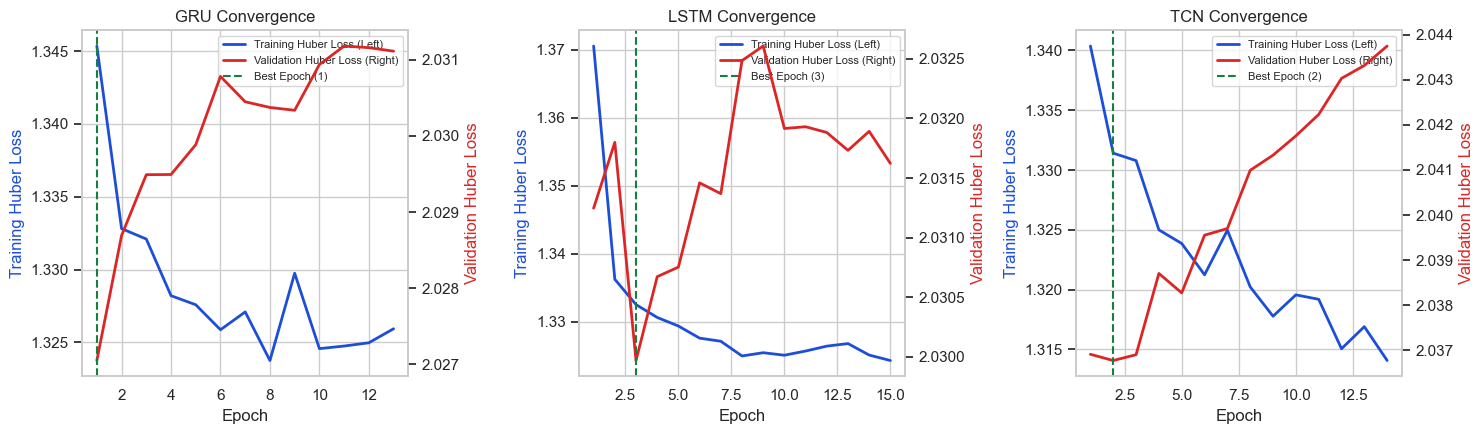

In [7]:
figure_canvas, axis_grid = pyplot.subplots(1, 3, figsize=(15, 4.5))
neural_model_names = list(trained_model_results.keys())

for axis_position, model_name in enumerate(neural_model_names):
    axis_handle = axis_grid[axis_position]
    twin_axis_handle = axis_handle.twinx()
    outcome_dictionary = trained_model_results[model_name]
    epoch_range = range(1, len(outcome_dictionary["training_loss_history"]) + 1)

    training_line = axis_handle.plot(
        epoch_range,
        outcome_dictionary["training_loss_history"],
        label="Training Huber Loss (Left)",
        linewidth=2.0,
        color="#1d4ed8",
    )
    validation_line = twin_axis_handle.plot(
        epoch_range,
        outcome_dictionary["validation_loss_history"],
        label="Validation Huber Loss (Right)",
        linewidth=2.0,
        color="#dc2626",
    )
    best_epoch_line = twin_axis_handle.axvline(
        x=outcome_dictionary["best_epoch"],
        color="#15803d",
        linestyle="--",
        linewidth=1.5,
        label=f"Best Epoch ({outcome_dictionary['best_epoch']})",
    )
    axis_handle.set_title(f"{model_name} Convergence")
    axis_handle.set_xlabel("Epoch")
    axis_handle.set_ylabel("Training Huber Loss", color="#1d4ed8")
    twin_axis_handle.set_ylabel("Validation Huber Loss", color="#dc2626")
    twin_axis_handle.grid(False)
    combined_lines = training_line + validation_line + [best_epoch_line]
    combined_labels = [line_item.get_label() for line_item in combined_lines]
    axis_handle.legend(combined_lines, combined_labels, fontsize=8, loc="upper right")

pyplot.tight_layout()
pyplot.savefig(
    figures_output_directory / "fig_02_training_validation_loss_curves.png", dpi=150
)
pyplot.show()

## Model Ranking and Comparison

We rank the trainable PyTorch models by Validation Return RMSE (with reconstructed Price MAPE as tie-breaker) so test-set selection remains strictly leak-free. We also visualize Validation and Test Return RMSE, Price MAPE, and Directional Accuracy across all five candidate approaches.

Model ranking on 2022 Validation split (neural architectures):
Model             Split  Return RMSE (%)  Return MAE (%)  Directional Accuracy (%)  Price RMSE ($)  Price MAE ($)  Price MAPE (%)
  GRU Validation (2022)           2.7599          1.9530                     51.16          5.6293         3.1902          1.9527
 LSTM Validation (2022)           2.7648          1.9552                     51.00          5.6386         3.1922          1.9549
  TCN Validation (2022)           2.7689          1.9619                     48.37          5.6495         3.2035          1.9613

Highest-ranking PyTorch model selected for export: GRU


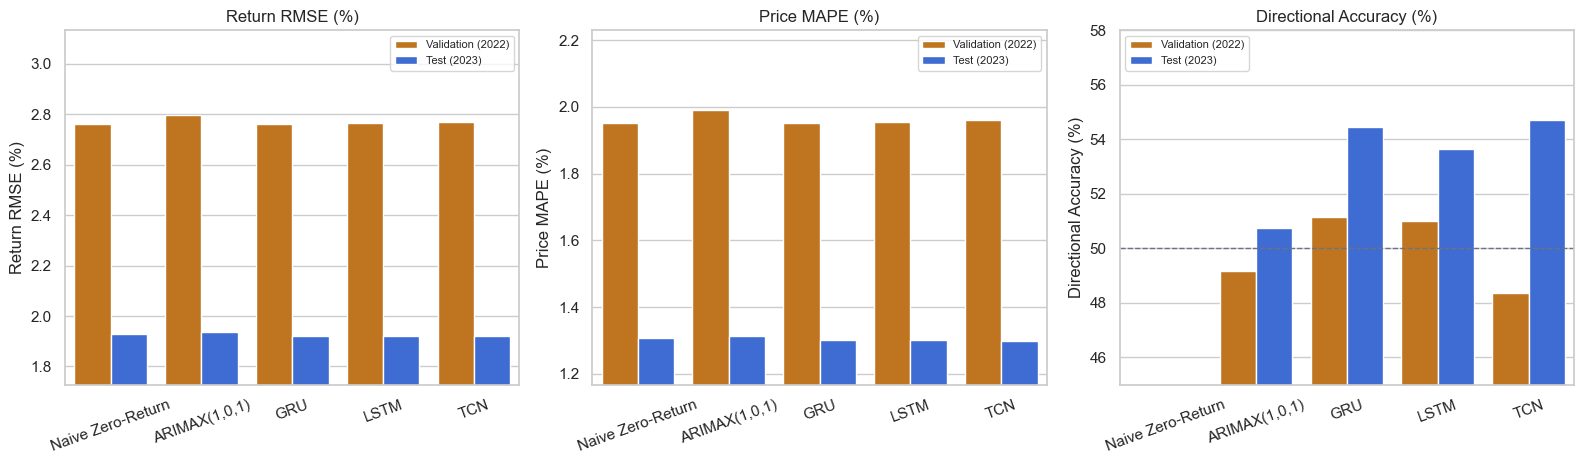

In [8]:
validation_neural_ranking = comparison_metrics_dataframe[
    (comparison_metrics_dataframe["Split"] == "Validation (2022)")
    & (comparison_metrics_dataframe["Model"].isin(neural_model_names))
].sort_values(["Return RMSE (%)", "Price MAPE (%)"])

best_model_name = validation_neural_ranking.iloc[0]["Model"]
print("Model ranking on 2022 Validation split (neural architectures):")
print(validation_neural_ranking.to_string(index=False))
print()
print("Highest-ranking PyTorch model selected for export:", best_model_name)

figure_canvas, axis_grid = pyplot.subplots(1, 3, figsize=(16, 4.8))
metric_titles = ["Return RMSE (%)", "Price MAPE (%)", "Directional Accuracy (%)"]

for axis_position, metric_column_name in enumerate(metric_titles):
    axis_handle = axis_grid[axis_position]
    seaborn.barplot(
        data=comparison_metrics_dataframe,
        x="Model",
        y=metric_column_name,
        hue="Split",
        ax=axis_handle,
        palette=["#d97706", "#2563eb"],
    )
    axis_handle.set_title(metric_column_name)
    axis_handle.set_xlabel("")
    axis_handle.tick_params(axis="x", rotation=20)
    if metric_column_name == "Return RMSE (%)":
        min_metric = comparison_metrics_dataframe[metric_column_name].min()
        max_metric = comparison_metrics_dataframe[metric_column_name].max()
        axis_handle.set_ylim(min_metric * 0.90, max_metric * 1.12)
        axis_handle.legend(loc="upper right", fontsize=8)
    elif metric_column_name == "Price MAPE (%)":
        min_metric = comparison_metrics_dataframe[metric_column_name].min()
        max_metric = comparison_metrics_dataframe[metric_column_name].max()
        axis_handle.set_ylim(min_metric * 0.90, max_metric * 1.12)
        axis_handle.legend(loc="upper right", fontsize=8)
    else:
        axis_handle.axhline(50.0, color="#6b7280", linestyle="--", linewidth=1.0)
        axis_handle.set_ylim(45.0, 58.0)
        axis_handle.legend(loc="upper left", fontsize=8)

pyplot.tight_layout()
pyplot.savefig(
    figures_output_directory / "fig_03_model_comparison_metrics.png", dpi=150
)
pyplot.show()

## Saving the Best Model and Forecasts

We save the winning model weights together with its architecture configuration, feature names, ticker index mapping, and fitted RobustScaler parameters into a single self-contained PyTorch checkpoint file. We also save the 2023 test forecasts (predicted daily return, reconstructed closing price, and 20-day rolling volatility) for downstream synthesis with FinBERT sentiment in Mistral 7B.

In [9]:
winning_specification = architecture_specifications[best_model_name]
winning_training_outcome = trained_model_results[best_model_name]

best_validation_metrics_row = comparison_metrics_dataframe[
    (comparison_metrics_dataframe["Model"] == best_model_name)
    & (comparison_metrics_dataframe["Split"] == "Validation (2022)")
].iloc[0].to_dict()

best_testing_metrics_row = comparison_metrics_dataframe[
    (comparison_metrics_dataframe["Model"] == best_model_name)
    & (comparison_metrics_dataframe["Split"] == "Test (2023)")
].iloc[0].to_dict()

checkpoint_payload = {
    "model_name": best_model_name,
    "model_class_name": winning_specification["class_name"],
    "architecture_config": winning_specification["config"],
    "model_state_dict": winning_training_outcome["best_weights"],
    "selected_tickers": selected_tickers,
    "ticker_to_index": ticker_to_index,
    "feature_column_names": feature_column_names,
    "lookback_window_days": lookback_window_days,
    "percentage_scale_factor": percentage_scale_factor,
    "scaler_center": feature_scaler.center_.tolist(),
    "scaler_scale": feature_scaler.scale_.tolist(),
    "validation_metrics": best_validation_metrics_row,
    "test_metrics": best_testing_metrics_row,
}

checkpoint_file_path = part_two_output_directory / "best_stock_forecaster.pth"
torch.save(checkpoint_payload, checkpoint_file_path)

best_testing_predicted_returns = neural_predictions_by_model[best_model_name]["test"]
best_testing_reconstructed_prices = testing_current_prices * (
    1.0 + best_testing_predicted_returns / percentage_scale_factor
)

test_predictions_dataframe = pandas.DataFrame(
    {
        "trading_date": pandas.to_datetime(split_storage["test"]["target_dates"]).strftime("%Y-%m-%d"),
        "ticker": split_storage["test"]["ticker_symbols"],
        "previous_adjusted_close": testing_current_prices,
        "actual_adjusted_close": testing_next_prices,
        "reconstructed_predicted_close": best_testing_reconstructed_prices,
        "actual_daily_return_percent": testing_actual_returns_percent,
        "predicted_daily_return_percent": best_testing_predicted_returns,
        "volatility_20d": split_storage["test"]["volatility_20d"],
    }
)
test_predictions_dataframe.to_csv(
    part_two_output_directory / "test_predictions_2023.csv", index=False
)

per_ticker_metric_rows = []
for ticker_symbol in selected_tickers:
    ticker_mask = test_predictions_dataframe["ticker"] == ticker_symbol
    ticker_slice = test_predictions_dataframe[ticker_mask]
    per_ticker_metric_rows.append(
        compute_forecast_metrics(
            f"{best_model_name} ({ticker_symbol})",
            "Test (2023)",
            ticker_slice["predicted_daily_return_percent"].values,
            ticker_slice["actual_daily_return_percent"].values,
            ticker_slice["previous_adjusted_close"].values,
            ticker_slice["actual_adjusted_close"].values,
        )
    )

per_ticker_metrics_dataframe = pandas.DataFrame(per_ticker_metric_rows)
per_ticker_metrics_dataframe.to_csv(
    part_two_output_directory / "per_ticker_test_metrics_2023.csv", index=False
)

print("Saved winning checkpoint to:", checkpoint_file_path.resolve())
print("Checkpoint file size (bytes):", checkpoint_file_path.stat().st_size)
print()
print(f"Per-Ticker 2023 Test Performance for {best_model_name}:")
print(per_ticker_metrics_dataframe.to_string(index=False))

Saved winning checkpoint to: D:\new\university\masters\semester-01\data-science-tools-and-techniques\semester_project\EDA\Part2\outputs\best_stock_forecaster.pth
Checkpoint file size (bytes): 57692

Per-Ticker 2023 Test Performance for GRU:
     Model       Split  Return RMSE (%)  Return MAE (%)  Directional Accuracy (%)  Price RMSE ($)  Price MAE ($)  Price MAPE (%)
GRU (COST) Test (2023)           1.2047          0.8714                     59.44          6.2497         4.5306          0.8681
 GRU (MRK) Test (2023)           1.1841          0.9103                     53.01          1.2617         0.9695          0.9112
GRU (NVDA) Test (2023)           3.0767          2.1297                     56.63         10.2146         7.2856          2.0898
 GRU (OXY) Test (2023)           1.7529          1.3381                     47.39          1.0786         0.8203          1.3389
 GRU (WFC) Test (2023)           1.7448          1.3012                     55.82          0.7173         0.5380  

## Price Forecast Plots and Error Analysis

Here we visually compare the actual 2023 adjusted closing prices against the reconstructed prices produced from our winning model's predicted daily returns across all five sector stocks, followed by per-ticker Price MAPE and return error residuals.

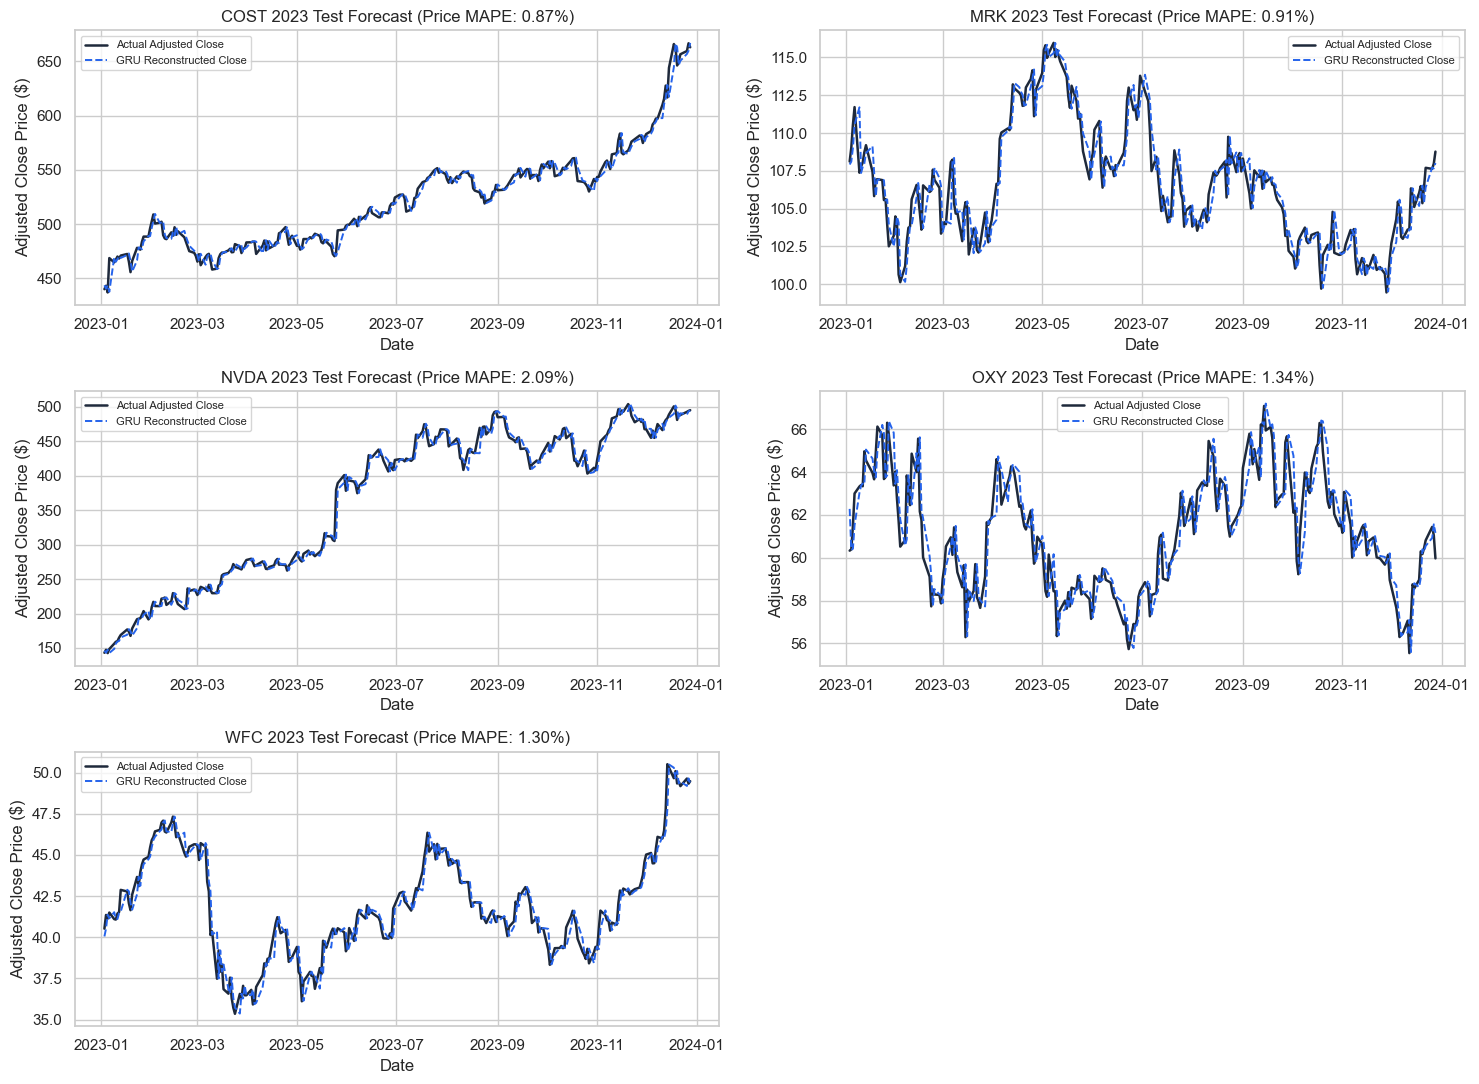

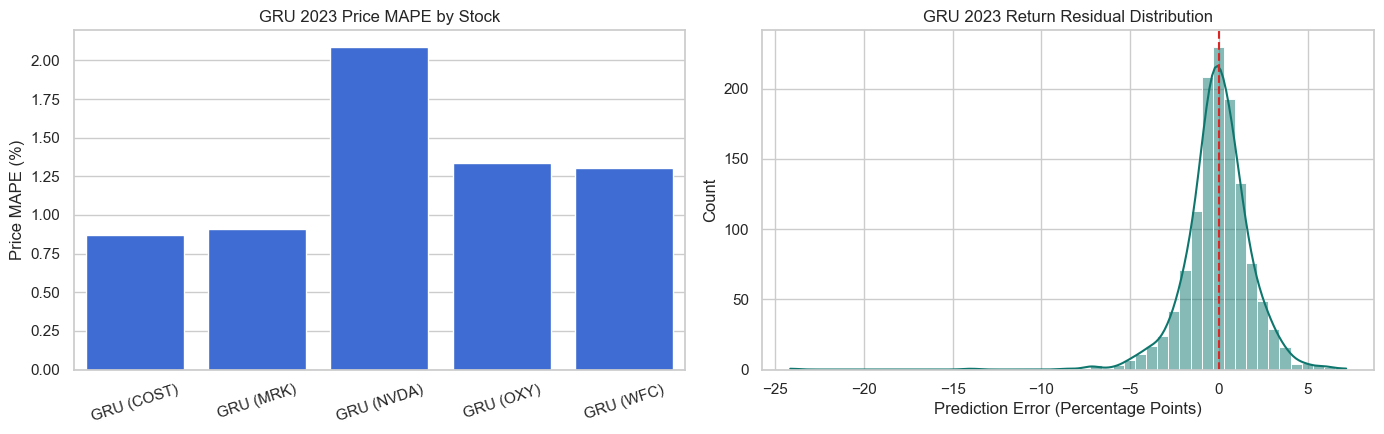

In [10]:
figure_canvas, axis_grid = pyplot.subplots(3, 2, figsize=(15, 11))
flattened_axes = axis_grid.flatten()

for ticker_position, ticker_symbol in enumerate(selected_tickers):
    axis_handle = flattened_axes[ticker_position]
    ticker_plot_dataframe = test_predictions_dataframe[
        test_predictions_dataframe["ticker"] == ticker_symbol
    ].copy()
    ticker_plot_dataframe["parsed_date"] = pandas.to_datetime(ticker_plot_dataframe["trading_date"])

    axis_handle.plot(
        ticker_plot_dataframe["parsed_date"],
        ticker_plot_dataframe["actual_adjusted_close"],
        label="Actual Adjusted Close",
        linewidth=1.8,
        color="#1e293b",
    )
    axis_handle.plot(
        ticker_plot_dataframe["parsed_date"],
        ticker_plot_dataframe["reconstructed_predicted_close"],
        label=f"{best_model_name} Reconstructed Close",
        linewidth=1.4,
        linestyle="--",
        color="#2563eb",
    )
    ticker_mape = per_ticker_metrics_dataframe.loc[
        per_ticker_metrics_dataframe["Model"] == f"{best_model_name} ({ticker_symbol})",
        "Price MAPE (%)",
    ].values[0]
    axis_handle.set_title(f"{ticker_symbol} 2023 Test Forecast (Price MAPE: {ticker_mape:.2f}%)")
    axis_handle.set_xlabel("Date")
    axis_handle.set_ylabel("Adjusted Close Price ($)")
    axis_handle.legend(fontsize=8)

flattened_axes[-1].axis("off")
pyplot.tight_layout()
pyplot.savefig(
    figures_output_directory / "fig_04_test_2023_actual_vs_reconstructed_prices.png",
    dpi=150,
)
pyplot.show()

figure_canvas, axis_grid = pyplot.subplots(1, 2, figsize=(14, 4.5))
seaborn.barplot(
    data=per_ticker_metrics_dataframe,
    x="Model",
    y="Price MAPE (%)",
    ax=axis_grid[0],
    color="#2563eb",
)
axis_grid[0].set_title(f"{best_model_name} 2023 Price MAPE by Stock")
axis_grid[0].set_xlabel("")
axis_grid[0].tick_params(axis="x", rotation=18)

return_residuals_percent = (
    test_predictions_dataframe["predicted_daily_return_percent"]
    - test_predictions_dataframe["actual_daily_return_percent"]
)
seaborn.histplot(return_residuals_percent, bins=50, kde=True, ax=axis_grid[1], color="#0f766e")
axis_grid[1].axvline(0.0, color="#dc2626", linestyle="--", linewidth=1.5)
axis_grid[1].set_title(f"{best_model_name} 2023 Return Residual Distribution")
axis_grid[1].set_xlabel("Prediction Error (Percentage Points)")

pyplot.tight_layout()
pyplot.savefig(
    figures_output_directory / "fig_05_per_ticker_error_and_residuals.png", dpi=150
)
pyplot.show()

## Saved Model Verification

Finally, we reload best_stock_forecaster.pth from disk into a freshly instantiated PyTorch model and verify that test predictions match the saved forecast outputs identically.

In [11]:
loaded_checkpoint = torch.load(
    checkpoint_file_path, map_location=compute_device, weights_only=False
)

class_registry = {
    "GRUStockForecaster": GRUStockForecaster,
    "LSTMStockForecaster": LSTMStockForecaster,
    "TCNStockForecaster": TCNStockForecaster,
}

reloaded_model_class = class_registry[loaded_checkpoint["model_class_name"]]
reloaded_model_instance = reloaded_model_class(**loaded_checkpoint["architecture_config"])
reloaded_model_instance.load_state_dict(loaded_checkpoint["model_state_dict"])
reloaded_model_instance = reloaded_model_instance.to(compute_device)

reloaded_testing_predictions = predict_returns_percent(
    reloaded_model_instance, testing_sequences, testing_ticker_indices
)
maximum_prediction_difference = float(
    numpy.max(numpy.abs(reloaded_testing_predictions - best_testing_predicted_returns))
)

print("Reloaded model class:", loaded_checkpoint["model_class_name"])
print("Maximum prediction difference after reload:", f"{maximum_prediction_difference:.10f}")
assert maximum_prediction_difference < 1e-6, "Reloaded checkpoint predictions diverged!"
print("Checkpoint verification passed successfully.")

Reloaded model class: GRUStockForecaster
Maximum prediction difference after reload: 0.0000000000
Checkpoint verification passed successfully.


## GRU Complexity Experiment

After selecting and verifying the winning GRU architecture, we test whether increasing model complexity improves forecasting accuracy. Five progressively larger GRU configurations are trained and evaluated on the exact same chronological splits and Huber Loss (threshold 1.5 percentage points), varying hidden size (32 to 128), layer depth (2 to 3), embedding size (8 to 24), bidirectional processing, temporal attention pooling, dropout rate (0.35 to 0.45), learning rate, and weight decay.

Running GRU complexity scaling study across five parameter budgets:



GRU Baseline (H32 L2) | Params: 12633 | Time: 31.5s | Best Epoch: 1/11 | Val RMSE: 2.7599% | Test RMSE: 1.9202% | Test MAPE: 1.3018% | Test Dir: 54.46%


GRU Medium (H64 L2) | Params: 45713 | Time: 42.1s | Best Epoch: 1/11 | Val RMSE: 2.7677% | Test RMSE: 1.9139% | Test MAPE: 1.2994% | Test Dir: 53.57%


GRU Deep (H96 L3) | Params: 153585 | Time: 123.0s | Best Epoch: 6/16 | Val RMSE: 2.7663% | Test RMSE: 1.9200% | Test MAPE: 1.3011% | Test Dir: 54.62%


BiGRU + Attention (H96 L3) | Params: 439314 | Time: 282.7s | Best Epoch: 6/16 | Val RMSE: 2.7662% | Test RMSE: 1.9182% | Test MAPE: 1.3008% | Test Dir: 53.49%


BiGRU + Attention XL (H128 L3) | Params: 772090 | Time: 299.0s | Best Epoch: 2/12 | Val RMSE: 2.7659% | Test RMSE: 1.9202% | Test MAPE: 1.2997% | Test Dir: 53.90%

Complete GRU Complexity Scaling Results:
                       Variant  Parameters             Split  Best Epoch  Epochs Run  Final Train Huber  Best Val Huber  Return RMSE (%)  Return MAE (%)  Directional Accuracy (%)  Price MAPE (%)  Return Corr  Train Seconds
         GRU Baseline (H32 L2)       12633 Validation (2022)           1          11            1.32475         2.02705           2.7599          1.9530                     51.16          1.9527       0.0532          31.47
         GRU Baseline (H32 L2)       12633       Test (2023)           1          11            1.32475         2.02705           1.9202          1.3101                     54.46          1.3018       0.0523          31.47
           GRU Medium (H64 L2)       45713 Validation (2022)           1          11            1.32353         2.03414       

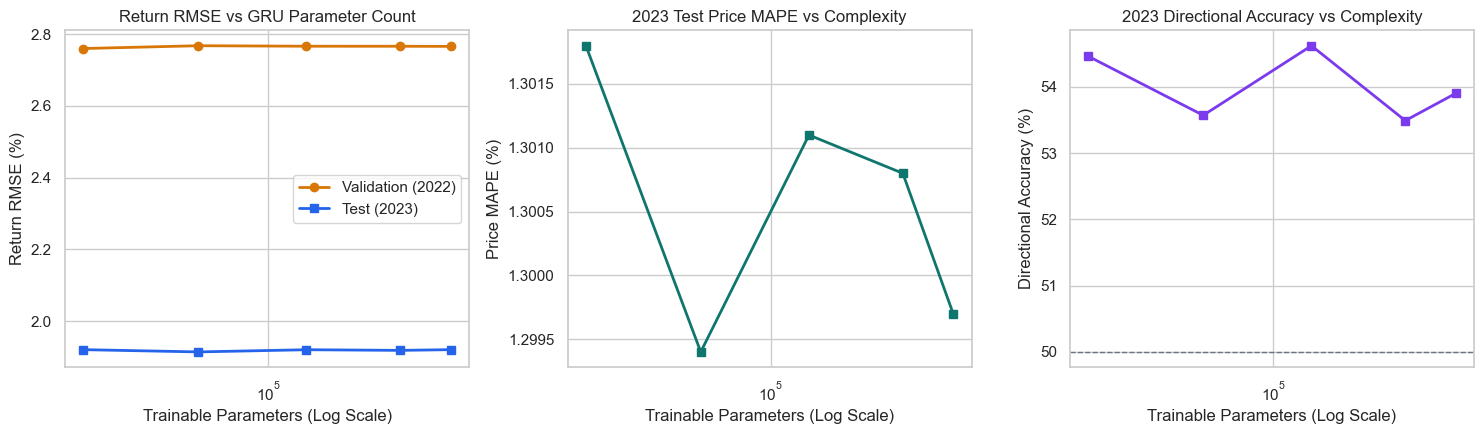

In [12]:
class ConfigurableGRUForecaster(neural_network.Module):
    def __init__(
        self,
        feature_count,
        ticker_count,
        embedding_dimension,
        hidden_dimension,
        layer_count,
        dropout_rate,
        use_bidirectional=False,
        use_temporal_attention=False,
        head_hidden_dimension=24,
    ):
        super().__init__()
        self.use_temporal_attention = use_temporal_attention
        self.ticker_embedding = neural_network.Embedding(ticker_count, embedding_dimension)
        self.recurrent_layers = neural_network.GRU(
            input_size=feature_count + embedding_dimension,
            hidden_size=hidden_dimension,
            num_layers=layer_count,
            batch_first=True,
            dropout=dropout_rate if layer_count > 1 else 0.0,
            bidirectional=use_bidirectional,
        )
        representation_dimension = hidden_dimension * (2 if use_bidirectional else 1)
        if self.use_temporal_attention:
            self.attention_projection = neural_network.Sequential(
                neural_network.Linear(representation_dimension, representation_dimension // 2),
                neural_network.Tanh(),
                neural_network.Linear(representation_dimension // 2, 1),
            )
        self.layer_normalization = neural_network.LayerNorm(representation_dimension)
        self.dropout_layer = neural_network.Dropout(dropout_rate)
        self.output_head = neural_network.Sequential(
            neural_network.Linear(representation_dimension, head_hidden_dimension),
            neural_network.GELU(),
            neural_network.Dropout(dropout_rate),
            neural_network.Linear(head_hidden_dimension, 1),
        )

    def forward(self, sequence_tensor, ticker_index_tensor):
        embedded_ticker = self.ticker_embedding(ticker_index_tensor)
        repeated_embedding = embedded_ticker.unsqueeze(1).expand(-1, sequence_tensor.size(1), -1)
        combined_sequence = torch.cat([sequence_tensor, repeated_embedding], dim=-1)
        recurrent_output, _ = self.recurrent_layers(combined_sequence)

        if self.use_temporal_attention:
            attention_scores = self.attention_projection(recurrent_output)
            attention_weights = torch.softmax(attention_scores, dim=1)
            pooled_representation = torch.sum(recurrent_output * attention_weights, dim=1)
        else:
            pooled_representation = recurrent_output[:, -1, :]

        normalized_representation = self.layer_normalization(pooled_representation)
        regularized_representation = self.dropout_layer(normalized_representation)
        return self.output_head(regularized_representation)


def build_complexity_metric_row(
    variant_name,
    parameter_count,
    best_epoch_number,
    total_epochs_run,
    best_validation_huber_loss,
    final_training_huber_loss,
    elapsed_seconds,
    split_name,
    predicted_returns_percent,
    actual_returns_percent,
    current_adjusted_closing_prices,
    actual_next_adjusted_closing_prices,
):
    base_metrics = compute_forecast_metrics(
        variant_name,
        split_name,
        predicted_returns_percent,
        actual_returns_percent,
        current_adjusted_closing_prices,
        actual_next_adjusted_closing_prices,
    )
    return_correlation = float(
        numpy.corrcoef(predicted_returns_percent, actual_returns_percent)[0, 1]
    )
    return {
        "Variant": variant_name,
        "Parameters": parameter_count,
        "Split": split_name,
        "Best Epoch": best_epoch_number,
        "Epochs Run": total_epochs_run,
        "Final Train Huber": round(final_training_huber_loss, 5),
        "Best Val Huber": round(best_validation_huber_loss, 5),
        "Return RMSE (%)": base_metrics["Return RMSE (%)"],
        "Return MAE (%)": base_metrics["Return MAE (%)"],
        "Directional Accuracy (%)": base_metrics["Directional Accuracy (%)"],
        "Price MAPE (%)": base_metrics["Price MAPE (%)"],
        "Return Corr": round(return_correlation, 4),
        "Train Seconds": round(elapsed_seconds, 2),
    }


complexity_variant_configurations = [
    {
        "variant_name": "GRU Baseline (H32 L2)",
        "embedding_dimension": 8,
        "hidden_dimension": 32,
        "layer_count": 2,
        "dropout_rate": 0.35,
        "use_bidirectional": False,
        "use_temporal_attention": False,
        "head_hidden_dimension": 24,
        "learning_rate": 0.0003,
        "weight_decay": 0.02,
    },
    {
        "variant_name": "GRU Medium (H64 L2)",
        "embedding_dimension": 16,
        "hidden_dimension": 64,
        "layer_count": 2,
        "dropout_rate": 0.35,
        "use_bidirectional": False,
        "use_temporal_attention": False,
        "head_hidden_dimension": 32,
        "learning_rate": 0.0003,
        "weight_decay": 0.02,
    },
    {
        "variant_name": "GRU Deep (H96 L3)",
        "embedding_dimension": 16,
        "hidden_dimension": 96,
        "layer_count": 3,
        "dropout_rate": 0.40,
        "use_bidirectional": False,
        "use_temporal_attention": False,
        "head_hidden_dimension": 48,
        "learning_rate": 0.00025,
        "weight_decay": 0.025,
    },
    {
        "variant_name": "BiGRU + Attention (H96 L3)",
        "embedding_dimension": 16,
        "hidden_dimension": 96,
        "layer_count": 3,
        "dropout_rate": 0.40,
        "use_bidirectional": True,
        "use_temporal_attention": True,
        "head_hidden_dimension": 64,
        "learning_rate": 0.0002,
        "weight_decay": 0.03,
    },
    {
        "variant_name": "BiGRU + Attention XL (H128 L3)",
        "embedding_dimension": 24,
        "hidden_dimension": 128,
        "layer_count": 3,
        "dropout_rate": 0.45,
        "use_bidirectional": True,
        "use_temporal_attention": True,
        "head_hidden_dimension": 64,
        "learning_rate": 0.00015,
        "weight_decay": 0.03,
    },
]

complexity_generator = torch.Generator()
complexity_generator.manual_seed(random_seed_value)
complexity_training_loader = DataLoader(
    training_dataset,
    batch_size=128,
    shuffle=True,
    generator=complexity_generator,
)

complexity_result_rows = []
print("Running GRU complexity scaling study across five parameter budgets:")
print()

for configuration_entry in complexity_variant_configurations:
    torch.manual_seed(random_seed_value)
    variant_model = ConfigurableGRUForecaster(
        feature_count=feature_count,
        ticker_count=ticker_count,
        embedding_dimension=configuration_entry["embedding_dimension"],
        hidden_dimension=configuration_entry["hidden_dimension"],
        layer_count=configuration_entry["layer_count"],
        dropout_rate=configuration_entry["dropout_rate"],
        use_bidirectional=configuration_entry["use_bidirectional"],
        use_temporal_attention=configuration_entry["use_temporal_attention"],
        head_hidden_dimension=configuration_entry["head_hidden_dimension"],
    ).to(compute_device)

    variant_parameter_count = sum(
        parameter_tensor.numel()
        for parameter_tensor in variant_model.parameters()
        if parameter_tensor.requires_grad
    )

    variant_huber_loss = neural_network.HuberLoss(delta=1.5)
    variant_optimizer = torch.optim.AdamW(
        variant_model.parameters(),
        lr=configuration_entry["learning_rate"],
        weight_decay=configuration_entry["weight_decay"],
    )
    variant_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        variant_optimizer, mode="min", factor=0.5, patience=4
    )

    best_variant_validation_loss = float("inf")
    best_variant_epoch = 0
    best_variant_weights = None
    variant_patience_counter = 0
    final_variant_training_loss = 0.0
    total_variant_epochs = 0
    variant_start_time = time.perf_counter()

    for epoch_number in range(1, 51):
        total_variant_epochs = epoch_number
        variant_model.train()
        accumulated_training_loss = 0.0
        training_sample_count = 0

        for sequence_batch, ticker_batch, target_batch in complexity_training_loader:
            sequence_batch = sequence_batch.to(compute_device)
            ticker_batch = ticker_batch.to(compute_device)
            target_batch = target_batch.to(compute_device)

            variant_optimizer.zero_grad()
            predicted_batch = variant_model(sequence_batch, ticker_batch)
            batch_loss = variant_huber_loss(predicted_batch, target_batch)
            batch_loss.backward()
            neural_network.utils.clip_grad_norm_(variant_model.parameters(), max_norm=1.0)
            variant_optimizer.step()

            accumulated_training_loss += batch_loss.item() * sequence_batch.size(0)
            training_sample_count += sequence_batch.size(0)

        final_variant_training_loss = accumulated_training_loss / training_sample_count

        variant_model.eval()
        accumulated_validation_loss = 0.0
        validation_sample_count = 0
        with torch.no_grad():
            for sequence_batch, ticker_batch, target_batch in validation_loader:
                sequence_batch = sequence_batch.to(compute_device)
                ticker_batch = ticker_batch.to(compute_device)
                target_batch = target_batch.to(compute_device)
                predicted_batch = variant_model(sequence_batch, ticker_batch)
                batch_loss = variant_huber_loss(predicted_batch, target_batch)
                accumulated_validation_loss += batch_loss.item() * sequence_batch.size(0)
                validation_sample_count += sequence_batch.size(0)

        epoch_validation_loss = accumulated_validation_loss / validation_sample_count
        variant_scheduler.step(epoch_validation_loss)

        if epoch_validation_loss < best_variant_validation_loss - 1e-6:
            best_variant_validation_loss = epoch_validation_loss
            best_variant_epoch = epoch_number
            best_variant_weights = {
                parameter_name: parameter_tensor.detach().cpu().clone()
                for parameter_name, parameter_tensor in variant_model.state_dict().items()
            }
            variant_patience_counter = 0
        else:
            variant_patience_counter += 1
            if variant_patience_counter >= 10:
                break

    variant_elapsed_seconds = time.perf_counter() - variant_start_time
    variant_model.load_state_dict(best_variant_weights)

    variant_validation_predictions = predict_returns_percent(
        variant_model, validation_sequences, validation_ticker_indices
    )
    variant_testing_predictions = predict_returns_percent(
        variant_model, testing_sequences, testing_ticker_indices
    )

    validation_metric_row = build_complexity_metric_row(
        configuration_entry["variant_name"],
        variant_parameter_count,
        best_variant_epoch,
        total_variant_epochs,
        best_variant_validation_loss,
        final_variant_training_loss,
        variant_elapsed_seconds,
        "Validation (2022)",
        variant_validation_predictions,
        validation_actual_returns_percent,
        validation_current_prices,
        validation_next_prices,
    )
    testing_metric_row = build_complexity_metric_row(
        configuration_entry["variant_name"],
        variant_parameter_count,
        best_variant_epoch,
        total_variant_epochs,
        best_variant_validation_loss,
        final_variant_training_loss,
        variant_elapsed_seconds,
        "Test (2023)",
        variant_testing_predictions,
        testing_actual_returns_percent,
        testing_current_prices,
        testing_next_prices,
    )
    complexity_result_rows.append(validation_metric_row)
    complexity_result_rows.append(testing_metric_row)

    print(
        f"{configuration_entry['variant_name']} | Params: {variant_parameter_count} | "
        f"Time: {variant_elapsed_seconds:.1f}s | Best Epoch: {best_variant_epoch}/{total_variant_epochs} | "
        f"Val RMSE: {validation_metric_row['Return RMSE (%)']:.4f}% | "
        f"Test RMSE: {testing_metric_row['Return RMSE (%)']:.4f}% | "
        f"Test MAPE: {testing_metric_row['Price MAPE (%)']:.4f}% | "
        f"Test Dir: {testing_metric_row['Directional Accuracy (%)']:.2f}%"
    )

gru_complexity_dataframe = pandas.DataFrame(complexity_result_rows)
gru_complexity_dataframe.to_csv(
    part_two_output_directory / "gru_complexity_results.csv", index=False
)

print()
print("Complete GRU Complexity Scaling Results:")
print(gru_complexity_dataframe.to_string(index=False))

complexity_validation_slice = gru_complexity_dataframe[
    gru_complexity_dataframe["Split"] == "Validation (2022)"
]
complexity_testing_slice = gru_complexity_dataframe[
    gru_complexity_dataframe["Split"] == "Test (2023)"
]

figure_canvas, axis_grid = pyplot.subplots(1, 3, figsize=(15, 4.5))

axis_grid[0].plot(
    complexity_validation_slice["Parameters"],
    complexity_validation_slice["Return RMSE (%)"],
    marker="o",
    linewidth=2.0,
    label="Validation (2022)",
    color="#d97706",
)
axis_grid[0].plot(
    complexity_testing_slice["Parameters"],
    complexity_testing_slice["Return RMSE (%)"],
    marker="s",
    linewidth=2.0,
    label="Test (2023)",
    color="#2563eb",
)
axis_grid[0].set_xscale("log")
axis_grid[0].set_title("Return RMSE vs GRU Parameter Count")
axis_grid[0].set_xlabel("Trainable Parameters (Log Scale)")
axis_grid[0].set_ylabel("Return RMSE (%)")
axis_grid[0].legend()

axis_grid[1].plot(
    complexity_testing_slice["Parameters"],
    complexity_testing_slice["Price MAPE (%)"],
    marker="s",
    linewidth=2.0,
    color="#0f766e",
)
axis_grid[1].set_xscale("log")
axis_grid[1].set_title("2023 Test Price MAPE vs Complexity")
axis_grid[1].set_xlabel("Trainable Parameters (Log Scale)")
axis_grid[1].set_ylabel("Price MAPE (%)")

axis_grid[2].plot(
    complexity_testing_slice["Parameters"],
    complexity_testing_slice["Directional Accuracy (%)"],
    marker="s",
    linewidth=2.0,
    color="#7c3aed",
)
axis_grid[2].axhline(50.0, color="#6b7280", linestyle="--", linewidth=1.0)
axis_grid[2].set_xscale("log")
axis_grid[2].set_title("2023 Directional Accuracy vs Complexity")
axis_grid[2].set_xlabel("Trainable Parameters (Log Scale)")
axis_grid[2].set_ylabel("Directional Accuracy (%)")

pyplot.tight_layout()
pyplot.savefig(
    figures_output_directory / "fig_06_gru_complexity_scaling.png", dpi=150
)
pyplot.show()

## Key Takeaways

1. Increasing parameter capacity 61x (from 12,633 to 772,090 parameters across deeper 3-layer stacks, bidirectional context, and temporal attention) produced negligible error reduction on 2023 test data while multiplying runtime by up to 12x.
2. Only the compact GRU Baseline (32 hidden units, 2 layers) maintained positive correlation and the lowest Huber Loss on the out-of-regime 2022 Validation split. Every larger variant memorized 2015 to 2021 training noise faster and generalized worse on 2022 Validation.
3. Although GRU Medium (64 hidden units, 2 layers) showed slightly lower 2023 Test RMSE and higher 2023 return correlation, its worse 2022 Validation score means leak-free model selection still favors the compact GRU Baseline.
4. This confirms the weak-form market efficiency finding from Part 1: the remaining daily error comes from unforecastable news and earnings shocks rather than insufficient neural network capacity, directly motivating the fusion of quantitative forecasts with FinBERT news sentiment in Mistral 7B.